# 03 · Análisis exploratorio integrado: tasas delictivas municipales (2022–2025)

**Fuentes:** denuncias del Ministerio Público (notebook 01) y población municipal del INE (notebook 02).

## Objetivos del notebook

1. **Integrar** ambas fuentes a nivel municipal, validando que el cruce sea completo y uno a uno.
2. Construir **tasas por cada 100,000 habitantes** para los 12 delitos.
3. Demostrar por qué se necesitan tasas y no conteos (**efecto tamaño**).
4. Analizar la **distribución**, los **valores atípicos**, la **estabilidad temporal** y las **correlaciones** de las tasas.
5. Evaluar de forma preliminar si los datos tienen **estructura de grupos** (estadístico de Hopkins y PCA).
6. Exportar la **base municipal integrada**, que será la entrada del preprocesamiento.

> Cada observación de la base final es **un municipio** (340) y las variables son las tasas de los 12 delitos, tal como establece la sección 5.4 del protocolo.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

from src.utilidades import (
    RUTA_PROCESSED, ANIOS_ESTUDIO, DELITOS, ORDEN_DELITOS, CODIGOS_DELITO,
    NOMBRE_CORTO, CODIGO_A_CORTO, FAMILIA_DELITO, COLOR, COLOR_FAMILIA,
    CMAP_SECUENCIAL, CMAP_DIVERGENTE, configurar_estilo, subtitulo, fuente,
    guardar_figura, formato_miles, normalizar_texto, resumen_distribucion,
    estadistico_hopkins,
)

configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CARPETA_FIG = "03_integrado"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
SEMILLA = 42
COLOR_DELITO = {DELITOS[d]: COLOR_FAMILIA[FAMILIA_DELITO[d]] for d in DELITOS}

## 1. Carga de las tablas procesadas

In [2]:
denuncias = pd.read_csv(RUTA_PROCESSED / "denuncias_municipio_anio_delito.csv", encoding="utf-8-sig")
poblacion = pd.read_csv(RUTA_PROCESSED / "poblacion_municipal_2015_2035.csv", encoding="utf-8-sig")
poblacion = poblacion[poblacion["Anio"].isin(ANIOS_ESTUDIO)].copy()

print(f"Denuncias: {denuncias.shape[0]:,} filas (municipio × año × delito)")
print(f"Población: {poblacion.shape[0]:,} filas (municipio × año, 2022–2025)")

Denuncias: 16,320 filas (municipio × año × delito)
Población: 1,360 filas (municipio × año, 2022–2025)


## 2. Homologación de nombres de municipio

Las dos fuentes escriben algunos nombres de manera diferente. Se compara primero con una **llave normalizada** (minúsculas, sin tildes, departamento + municipio) para que las diferencias de acentos o mayúsculas no cuenten.

In [3]:
def llave(depto, muni):
    return normalizar_texto(depto) + " | " + normalizar_texto(muni)

mun_mp = denuncias[["Departamento", "Municipio"]].drop_duplicates()
mun_mp["llave"] = [llave(d, m) for d, m in zip(mun_mp["Departamento"], mun_mp["Municipio"])]

mun_ine = poblacion[["Codigo_Municipio", "Departamento", "Municipio"]].drop_duplicates()
mun_ine["llave"] = [llave(d, m) for d, m in zip(mun_ine["Departamento"], mun_ine["Municipio"])]

solo_mp = mun_mp[~mun_mp["llave"].isin(mun_ine["llave"])].sort_values("llave")
solo_ine = mun_ine[~mun_ine["llave"].isin(mun_mp["llave"])].sort_values("llave")
print(f"Coinciden directamente: {mun_mp['llave'].isin(mun_ine['llave']).sum()} de 340")
print(f"Solo en MP: {len(solo_mp)}   Solo en INE: {len(solo_ine)}")
print("\nSin coincidencia en el MP:  ", ", ".join(solo_mp["Municipio"]))
print("Sin coincidencia en el INE: ", ", ".join(solo_ine["Municipio"]))

Coinciden directamente: 328 de 340
Solo en MP: 12   Solo en INE: 12

Sin coincidencia en el MP:   La Tinta, Lanquín, Tucurú, Pochuta, Tecpán, Yepocapa, Olintepeque, Ixcán, Nebaj, Uspantán, Alotenango, San Bartolo
Sin coincidencia en el INE:  San Agustín Lanquín, San Miguel Tucurú, Santa Catalina La Tinta, San Miguel Pochuta, San Pedro Yepocapa, Tecpán Guatemala, San Juan Olintepeque, Playa Grande Ixcán, San Miguel Uspantán, Santa María Nebaj, San Juan Alotenango, San Bartolo Aguas Calientes


Las 12 diferencias son **el mismo municipio con nombre corto (MP) o nombre oficial completo (INE)**, por ejemplo *Tecpán* y *Tecpán Guatemala*. Se resuelven con un diccionario **explícito** que queda documentado, en lugar de una coincidencia aproximada automática que podría unir municipios equivocados.

In [4]:
# Nombre en el MP (normalizado) -> nombre oficial del INE (normalizado)
EQUIVALENCIAS_MP_INE = {
    "alta verapaz | la tinta": "alta verapaz | santa catalina la tinta",
    "alta verapaz | lanquin": "alta verapaz | san agustin lanquin",
    "alta verapaz | tucuru": "alta verapaz | san miguel tucuru",
    "chimaltenango | pochuta": "chimaltenango | san miguel pochuta",
    "chimaltenango | tecpan": "chimaltenango | tecpan guatemala",
    "chimaltenango | yepocapa": "chimaltenango | san pedro yepocapa",
    "quetzaltenango | olintepeque": "quetzaltenango | san juan olintepeque",
    "quiche | ixcan": "quiche | playa grande ixcan",
    "quiche | nebaj": "quiche | santa maria nebaj",
    "quiche | uspantan": "quiche | san miguel uspantan",
    "sacatepequez | alotenango": "sacatepequez | san juan alotenango",
    "totonicapan | san bartolo": "totonicapan | san bartolo aguas calientes",
}

mun_mp["llave_ine"] = mun_mp["llave"].replace(EQUIVALENCIAS_MP_INE)
catalogo = mun_mp.merge(
    mun_ine[["llave", "Codigo_Municipio", "Municipio"]].rename(
        columns={"llave": "llave_ine", "Municipio": "Municipio_INE"}),
    on="llave_ine", how="left")

# Tabla de equivalencias aplicadas (para el anexo de la tesis)
display(catalogo.loc[catalogo["llave"].isin(EQUIVALENCIAS_MP_INE),
                     ["Codigo_Municipio", "Departamento", "Municipio", "Municipio_INE"]]
        .rename(columns={"Municipio": "Nombre en MP", "Municipio_INE": "Nombre oficial INE"})
        .sort_values("Codigo_Municipio").reset_index(drop=True))

validacion_cruce = pd.Series({
    "Municipios MP": len(mun_mp),
    "Municipios INE": len(mun_ine),
    "MP sin código INE": int(catalogo["Codigo_Municipio"].isna().sum()),
    "Códigos INE asignados más de una vez": int(catalogo["Codigo_Municipio"].duplicated().sum()),
    "Códigos INE sin municipio MP": int((~mun_ine["Codigo_Municipio"].isin(catalogo["Codigo_Municipio"])).sum()),
}, name="resultado")
display(validacion_cruce.to_frame())
assert validacion_cruce.iloc[2:].sum() == 0, "El cruce no es uno a uno"

,Codigo_Municipio,Departamento,Nombre en MP,Nombre oficial INE
0,314,Sacatepéquez,Alotenango,San Juan Alotenango
1,406,Chimaltenango,Tecpán,Tecpán Guatemala
2,408,Chimaltenango,Pochuta,San Miguel Pochuta
3,412,Chimaltenango,Yepocapa,San Pedro Yepocapa
4,808,Totonicapán,San Bartolo,San Bartolo Aguas Calientes
5,903,Quetzaltenango,Olintepeque,San Juan Olintepeque
6,1413,Quiché,Nebaj,Santa María Nebaj
7,1415,Quiché,Uspantán,San Miguel Uspantán
8,1420,Quiché,Ixcán,Playa Grande Ixcán
9,1606,Alta Verapaz,Tucurú,San Miguel Tucurú


,resultado
Municipios MP,340
Municipios INE,340
MP sin código INE,0
Códigos INE asignados más de una vez,0
Códigos INE sin municipio MP,0


El cruce es **completo y uno a uno** (340 ↔ 340). Los 6 municipios homónimos se resuelven bien porque la llave incluye el departamento. Desde aquí se usa el **código INE** como identificador y el **nombre oficial del INE** para las etiquetas.

## 3. Construcción de indicadores

Para cada municipio $m$ y delito $d$ se calcula la **tasa promedio anual por 100,000 habitantes** del periodo 2022–2025:

$$\text{Tasa}_{m,d} = \frac{\sum_{a=2022}^{2025} \text{Denuncias}_{m,d,a}}{\sum_{a=2022}^{2025} \text{Población}_{m,a}} \times 100{,}000$$

Sumar denuncias y población de los 4 años (en lugar de promediar 4 tasas anuales) da **más peso a más información** y reduce la volatilidad de los municipios pequeños. También se calculan las tasas **anuales** para evaluar su estabilidad.

In [5]:
denuncias = denuncias.merge(catalogo[["Departamento", "Municipio", "Codigo_Municipio"]],
                            on=["Departamento", "Municipio"], how="left")
denuncias = denuncias.rename(columns={"Municipio": "Municipio_MP"}).drop(columns=["Departamento"])

anual = denuncias.merge(poblacion, on=["Codigo_Municipio", "Anio"], how="left", validate="many_to_one")
assert anual["Poblacion"].notna().all()
anual["Tasa"] = anual["Denuncias"] / anual["Poblacion"] * 100_000

# Tasas anuales en formato ancho: (municipio, año) × delito
tasas_anuales = anual.pivot_table(index=["Codigo_Municipio", "Anio"], columns="Codigo_Delito",
                                  values="Tasa")[CODIGOS_DELITO]

# Tasa del periodo 2022–2025
conteos = anual.pivot_table(index="Codigo_Municipio", columns="Codigo_Delito",
                            values="Denuncias", aggfunc="sum")[CODIGOS_DELITO]
pob_periodo = poblacion.groupby("Codigo_Municipio")["Poblacion"].sum()   # persona-años
tasas = conteos.div(pob_periodo, axis=0) * 100_000

info = (poblacion.groupby(["Codigo_Municipio", "Departamento", "Municipio"])["Poblacion"]
        .mean().rename("Poblacion_prom").reset_index().set_index("Codigo_Municipio"))
info["Etiqueta"] = info["Municipio"] + " (" + info["Departamento"] + ")"
info["Denuncias_total"] = conteos.sum(axis=1)
info["Tasa_total"] = info["Denuncias_total"] / pob_periodo * 100_000

print(f"Matriz de tasas: {tasas.shape[0]} municipios × {tasas.shape[1]} delitos")
print(f"¿Se conserva el total de denuncias? {conteos.values.sum() == denuncias['Denuncias'].sum()}")
display(tasas.join(info[["Etiqueta"]]).set_index("Etiqueta").head().rename(columns=CODIGO_A_CORTO))

Matriz de tasas: 340 municipios × 12 delitos
¿Se conserva el total de denuncias? True


,Homicidio,Asesinato,Robo,Robo agravado,Hurto,Hurto agravado,Extorsión,Violación,Violación agravada,Violación c. esp. agrav.,Agresión sexual,Agresión sexual agrav.
Etiqueta,,,,,,,,,,,,
Guatemala (Guatemala),55.56,17.85,626.35,490.10,807.22,376.81,393.78,34.22,2.65,1.00,25.63,5.82
Santa Catarina Pinula (Guatemala),35.00,23.61,129.17,134.86,209.40,148.80,342.56,21.05,1.14,1.14,15.93,3.13
San José Pinula (Guatemala),32.31,13.53,149.95,140.84,178.67,157.13,308.74,29.00,3.59,0.55,19.05,7.46
San José del Golfo (Guatemala),14.67,11.73,88.01,70.41,152.55,108.54,161.35,11.73,8.80,0.00,14.67,8.80
Palencia (Guatemala),36.20,4.98,80.05,54.14,199.62,62.78,207.26,24.25,1.66,0.66,17.60,7.97


### 3.1 Tasas nacionales de referencia

In [6]:
tasa_nacional = conteos.sum() / pob_periodo.sum() * 100_000
display(tasa_nacional.rename(CODIGO_A_CORTO).sort_values(ascending=False)
        .to_frame("Tasa nacional promedio anual (por 100 mil)"))
print(f"Tasa total nacional (12 delitos): {conteos.values.sum() / pob_periodo.sum() * 1e5:,.1f} por 100 mil hab. al año")

,Tasa nacional promedio anual (por 100 mil)
Codigo_Delito,
Hurto,159.69
Extorsión,119.35
Robo agravado,92.41
Hurto agravado,87.24
Robo,87.01
Violación,25.30
Homicidio,19.49
Agresión sexual,12.69
Asesinato,4.84


Tasa total nacional (12 delitos): 613.7 por 100 mil hab. al año


## 4. ¿Por qué tasas? El efecto tamaño

Si las denuncias fueran estrictamente proporcionales a la población, en escala log–log los municipios formarían una recta con pendiente **1**. Una pendiente mayor que 1 significa que los municipios grandes denuncian **más que proporcionalmente** (efecto urbano).

Pendiente (elasticidad) = 1.07   IC 95 % ≈ [0.97, 1.17]   R² = 0.57


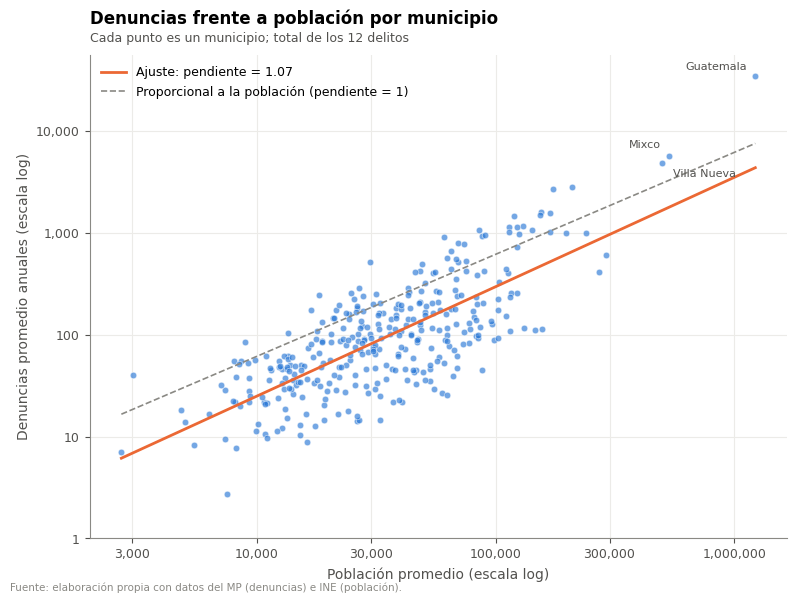

In [7]:
x = np.log10(info["Poblacion_prom"])
y = np.log10(info["Denuncias_total"] / 4)
reg = stats.linregress(x, y)
print(f"Pendiente (elasticidad) = {reg.slope:.2f}   IC 95 % ≈ [{reg.slope - 1.96*reg.stderr:.2f}, "
      f"{reg.slope + 1.96*reg.stderr:.2f}]   R² = {reg.rvalue**2:.2f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, s=22, color=COLOR["azul"], alpha=0.65, edgecolor="white", linewidth=0.5)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, reg.intercept + reg.slope * xs, color=COLOR["naranja"],
        label=f"Ajuste: pendiente = {reg.slope:.2f}")
ax.plot(xs, np.log10(tasa_nacional.sum() / 1e5) + xs, color=COLOR["gris"], linestyle="--",
        linewidth=1.2, label="Proporcional a la población (pendiente = 1)")
for cod, desp in zip(info.nlargest(3, "Poblacion_prom").index, [(-6, 4), (-6, 6), (8, -10)]):
    ax.annotate(info.loc[cod, "Municipio"], (x[cod], y[cod]), textcoords="offset points",
                xytext=desp, ha="right" if desp[0] < 0 else "left", fontsize=8,
                color=COLOR["texto_sec"])
ticks_x = [3e3, 1e4, 3e4, 1e5, 3e5, 1e6]
ax.set_xticks(np.log10(ticks_x), [f"{t:,.0f}" for t in ticks_x])
ticks_y = [1, 10, 100, 1_000, 10_000]
ax.set_yticks(np.log10(ticks_y), [f"{t:,.0f}" for t in ticks_y])
ax.set_xlabel("Población promedio (escala log)")
ax.set_ylabel("Denuncias promedio anuales (escala log)")
ax.set_title("Denuncias frente a población por municipio")
subtitulo(ax, "Cada punto es un municipio; total de los 12 delitos")
ax.legend(loc="upper left")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "01_denuncias_vs_poblacion", CARPETA_FIG)
plt.show()

Ahora se compara, para cada delito, cuánto se relaciona con el tamaño del municipio **antes** (conteos) y **después** (tasas) de normalizar. Lo ideal es que las tasas dependan poco de la población.

,Conteos,Tasas
Codigo_Delito,,
Homicidio,0.59,0.14
Asesinato,0.60,0.30
Robo,0.66,0.11
Robo agravado,0.47,-0.01
Hurto,0.69,0.03
Hurto agravado,0.55,0.02
Extorsión,0.55,0.01
Violación,0.86,0.11
Violación agravada,0.72,0.10


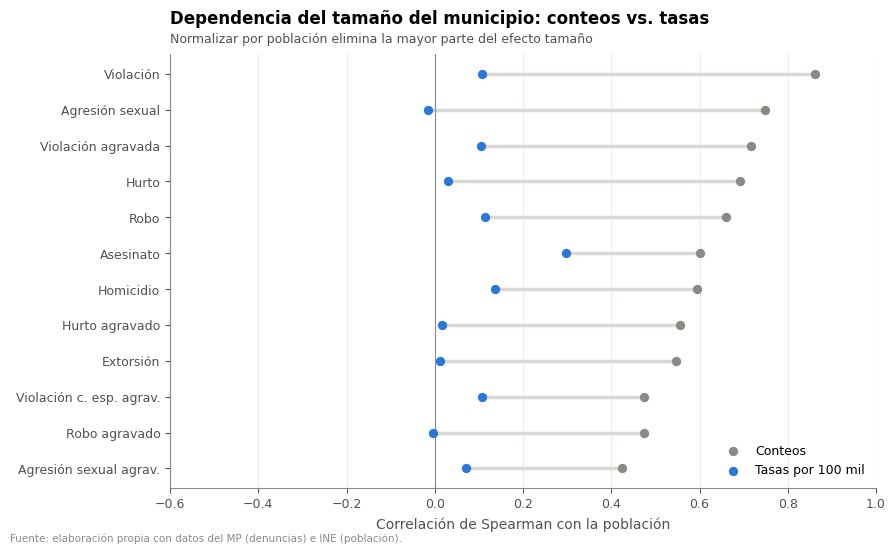

In [8]:
rho_conteo = conteos.apply(lambda c: stats.spearmanr(c, info["Poblacion_prom"])[0])
rho_tasa = tasas.apply(lambda c: stats.spearmanr(c, info["Poblacion_prom"])[0])
efecto = pd.DataFrame({"Conteos": rho_conteo, "Tasas": rho_tasa}).rename(index=CODIGO_A_CORTO)
display(efecto.round(2))

orden = efecto.sort_values("Conteos").index
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, d in enumerate(orden):
    ax.plot([efecto.loc[d, "Tasas"], efecto.loc[d, "Conteos"]], [i, i],
            color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.scatter(efecto.loc[orden, "Conteos"], range(len(orden)), color=COLOR["gris"], s=45,
           zorder=2, label="Conteos")
ax.scatter(efecto.loc[orden, "Tasas"], range(len(orden)), color=COLOR["azul"], s=45,
           zorder=3, label="Tasas por 100 mil")
ax.axvline(0, color=COLOR["gris"], linewidth=0.8)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(-0.6, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación de Spearman con la población")
ax.set_title("Dependencia del tamaño del municipio: conteos vs. tasas")
subtitulo(ax, "Normalizar por población elimina la mayor parte del efecto tamaño")
ax.legend(loc="lower right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "02_efecto_tamano", CARPETA_FIG)
plt.show()

## 5. Distribución de las tasas

### 5.1 Estadísticos descriptivos

In [9]:
resumen_tasas = resumen_distribucion(tasas).rename(index=CODIGO_A_CORTO)
display(resumen_tasas.round(2))

,media,mediana,desv_est,CV,min,Q1,Q3,max,asimetria,curtosis,pct_ceros
Homicidio,14.37,8.24,15.35,1.07,0.00,2.98,21.35,89.85,1.55,2.41,6.18
Asesinato,2.78,1.54,3.66,1.32,0.00,0.00,3.93,23.61,2.04,4.92,27.94
Robo,34.10,18.59,50.70,1.49,0.00,9.48,38.16,626.35,5.94,56.44,0.29
Robo agravado,49.17,22.37,69.23,1.41,0.00,8.25,61.39,493.49,3.12,13.11,1.18
Hurto,92.82,61.47,98.58,1.06,4.78,35.76,110.09,807.22,3.19,14.52,0.00
Hurto agravado,56.72,36.42,63.80,1.12,0.00,14.87,71.92,404.69,2.40,7.44,0.29
Extorsión,86.78,65.90,80.04,0.92,0.00,24.33,124.60,447.13,1.41,2.22,0.29
Violación,24.00,22.40,11.70,0.49,3.12,14.68,31.98,66.20,0.64,0.34,0.00
Violación agravada,3.19,2.52,2.94,0.92,0.00,1.29,4.03,20.95,1.99,6.09,11.47
Violación c. esp. agrav.,1.27,0.71,1.93,1.52,0.00,0.00,1.76,18.54,3.82,23.42,36.76


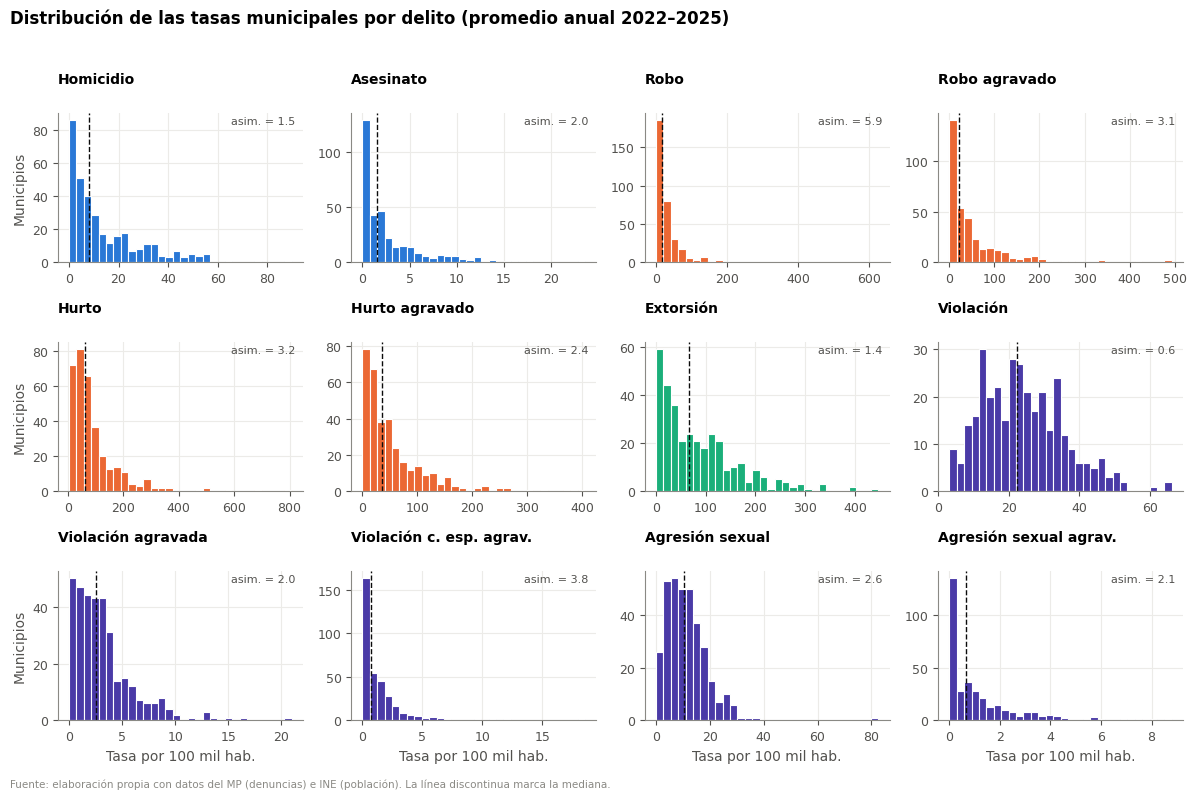

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for ax, cod in zip(axes.flat, CODIGOS_DELITO):
    ax.hist(tasas[cod], bins=30, color=COLOR_DELITO[cod], edgecolor="white", linewidth=0.8)
    ax.axvline(tasas[cod].median(), color=COLOR["texto"], linestyle="--", linewidth=1)
    ax.set_title(CODIGO_A_CORTO[cod], fontsize=10)
    ax.text(0.97, 0.93, f"asim. = {stats.skew(tasas[cod]):.1f}", transform=ax.transAxes,
            ha="right", fontsize=8, color=COLOR["texto_sec"])
for ax in axes[-1]:
    ax.set_xlabel("Tasa por 100 mil hab.")
for ax in axes[:, 0]:
    ax.set_ylabel("Municipios")
fig.suptitle("Distribución de las tasas municipales por delito (promedio anual 2022–2025)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fuente(fig, FUENTE + " La línea discontinua marca la mediana.")
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
guardar_figura(fig, "03_histogramas_tasas", CARPETA_FIG)
plt.show()

### 5.2 Normalidad y efecto de una transformación logarítmica

Los algoritmos basados en distancias (K-means, jerárquico, GMM) funcionan mejor cuando las variables no tienen colas extremas. Se evalúa:

- La prueba de normalidad de **D'Agostino–Pearson** (H₀: la variable es normal).
- Cuánto se reduce la asimetría con la transformación $\log(1 + \text{tasa})$, que conserva los ceros.

,Asimetría original,Asimetría log(1+x),Curtosis original,Curtosis log(1+x),p-valor normalidad (original),p-valor normalidad (log)
Codigo_Delito,,,,,,
Homicidio,1.55,-0.19,2.40,-0.77,0.00,0.00
Asesinato,2.04,0.45,4.92,-0.84,0.00,0.00
Robo,5.94,0.19,56.44,0.03,0.00,0.33
Robo agravado,3.12,-0.11,13.11,-0.59,0.00,0.01
Hurto,3.19,0.01,14.52,-0.10,0.00,0.97
Hurto agravado,2.40,-0.25,7.44,-0.41,0.00,0.03
Extorsión,1.42,-0.62,2.22,-0.19,0.00,0.00
Violación,0.64,-0.64,0.34,0.25,0.00,0.00
Violación agravada,1.99,-0.10,6.09,-0.31,0.00,0.37


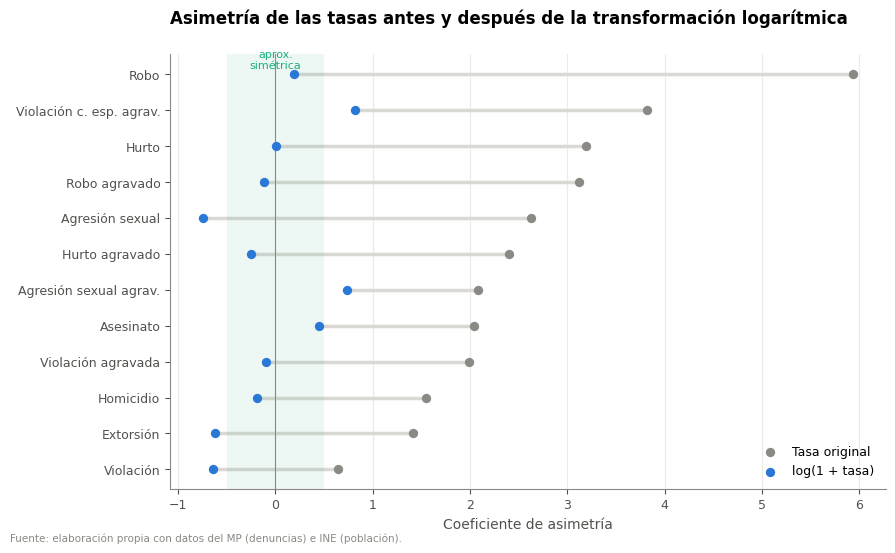

In [11]:
tasas_log = np.log1p(tasas)
normalidad = pd.DataFrame({
    "Asimetría original": tasas.apply(stats.skew),
    "Asimetría log(1+x)": tasas_log.apply(stats.skew),
    "Curtosis original": tasas.apply(stats.kurtosis),
    "Curtosis log(1+x)": tasas_log.apply(stats.kurtosis),
    "p-valor normalidad (original)": tasas.apply(lambda c: stats.normaltest(c).pvalue),
    "p-valor normalidad (log)": tasas_log.apply(lambda c: stats.normaltest(c).pvalue),
}).rename(index=CODIGO_A_CORTO)
display(normalidad.round(3))

orden = normalidad["Asimetría original"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, d in enumerate(orden):
    ax.plot(normalidad.loc[d, ["Asimetría log(1+x)", "Asimetría original"]], [i, i],
            color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.scatter(normalidad.loc[orden, "Asimetría original"], range(len(orden)), s=45,
           color=COLOR["gris"], zorder=2, label="Tasa original")
ax.scatter(normalidad.loc[orden, "Asimetría log(1+x)"], range(len(orden)), s=45,
           color=COLOR["azul"], zorder=3, label="log(1 + tasa)")
ax.axvline(0, color=COLOR["gris"], linewidth=0.8)
ax.axvspan(-0.5, 0.5, color=COLOR["aqua"], alpha=0.08, lw=0)
ax.text(0, len(orden) - 0.3, "aprox.\nsimétrica", ha="center", va="top", fontsize=8, color=COLOR["aqua"])
ax.set_yticks(range(len(orden)), orden)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente de asimetría")
ax.set_title("Asimetría de las tasas antes y después de la transformación logarítmica")
ax.legend(loc="lower right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "04_asimetria_transformacion", CARPETA_FIG)
plt.show()

### 5.3 Boxplots en escala transformada

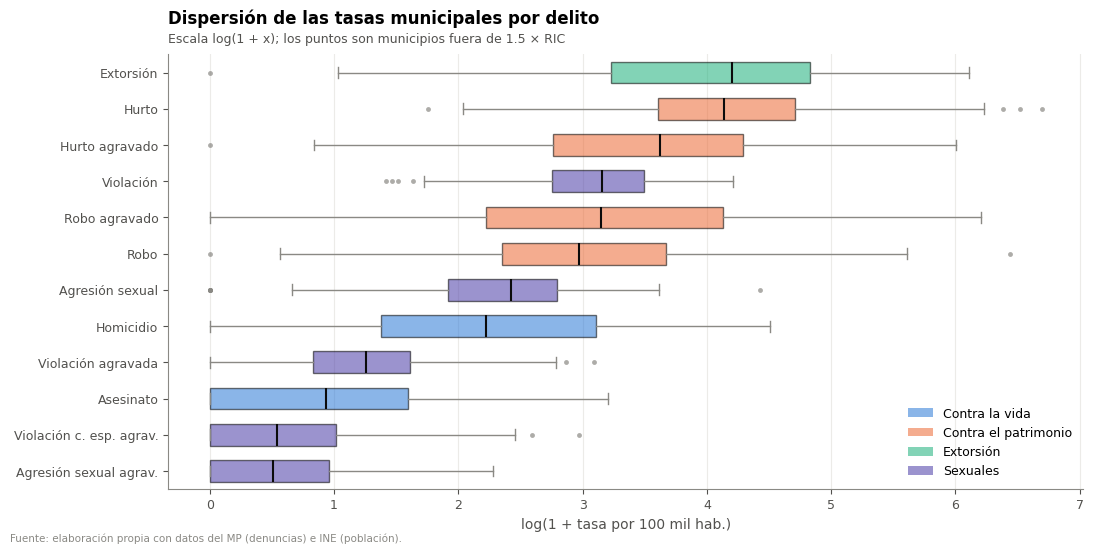

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.5))
orden_box = tasas_log.median().sort_values().index
bp = ax.boxplot([tasas_log[c] for c in orden_box], vert=False, patch_artist=True, widths=0.6,
                medianprops=dict(color=COLOR["texto"], linewidth=1.5),
                flierprops=dict(marker="o", markersize=3.5, markerfacecolor=COLOR["gris"],
                                markeredgecolor="none", alpha=0.7),
                whiskerprops=dict(color=COLOR["gris"]), capprops=dict(color=COLOR["gris"]))
for caja, c in zip(bp["boxes"], orden_box):
    caja.set_facecolor(COLOR_DELITO[c]); caja.set_alpha(0.55)
ax.set_yticks(range(1, 13), [CODIGO_A_CORTO[c] for c in orden_box])
ax.grid(axis="y", visible=False)
ax.set_xlabel("log(1 + tasa por 100 mil hab.)")
ax.set_title("Dispersión de las tasas municipales por delito")
subtitulo(ax, "Escala log(1 + x); los puntos son municipios fuera de 1.5 × RIC")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.55) for c in COLOR_FAMILIA.values()]
ax.legend(handles, COLOR_FAMILIA.keys(), loc="lower right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "05_boxplot_tasas_log", CARPETA_FIG)
plt.show()

## 6. Tasas y tamaño del municipio: gráfico de embudo (*funnel plot*)

El gráfico de embudo muestra la tasa de cada municipio frente a su población, junto con los **límites de control de Poisson al 95 % y 99.8 %** alrededor de la tasa nacional. Los límites se abren para los municipios pequeños: ahí el azar por sí solo produce tasas extremas.

- Un municipio **fuera** de los límites tiene una tasa que difícilmente se explica por azar: es una **señal real**.
- Un municipio pequeño con tasa alta pero **dentro** de los límites puede ser solo **ruido estadístico**.

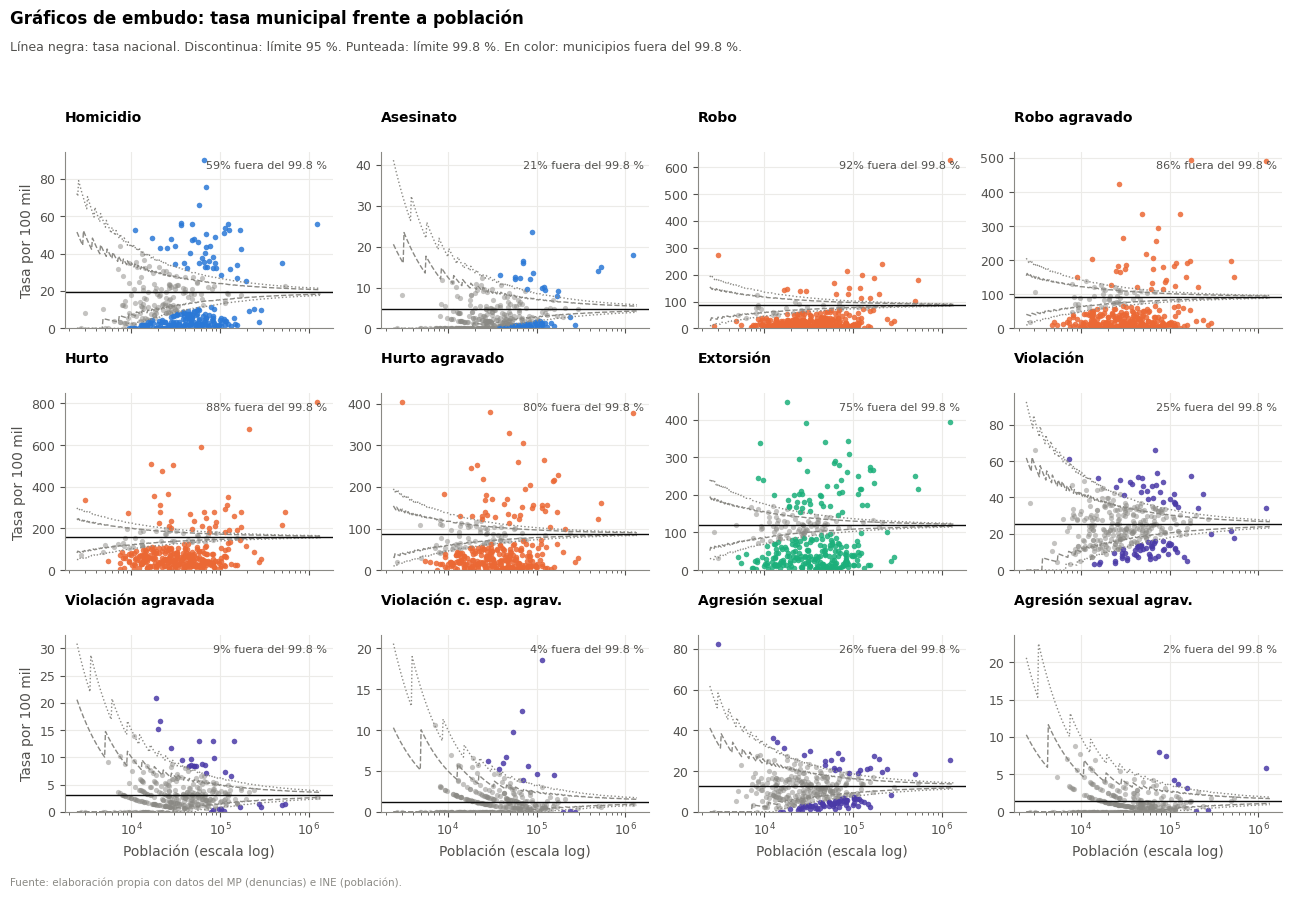

,% municipios fuera del 99.8 %,Tasa nacional
Agresión sexual agrav.,2.40,1.40
Violación c. esp. agrav.,4.10,1.20
Violación agravada,8.80,3.10
Asesinato,20.90,4.80
Violación,25.00,25.30
Agresión sexual,25.60,12.70
Homicidio,58.50,19.50
Extorsión,75.00,119.30
Hurto agravado,79.70,87.20
Robo agravado,85.90,92.40


In [13]:
def limites_poisson(tasa_ref, persona_anios, p):
    lam = tasa_ref / 1e5 * persona_anios
    return (stats.poisson.ppf(p, lam) / persona_anios * 1e5,
            stats.poisson.ppf(1 - p, lam) / persona_anios * 1e5)

def grafico_embudo(ax, cod):
    tasa_ref = tasa_nacional[cod]
    pa = pob_periodo
    xs = np.logspace(np.log10(pa.min() * 0.9), np.log10(pa.max() * 1.1), 300)
    for p, estilo in [(0.025, "--"), (0.001, ":")]:
        inf, sup = limites_poisson(tasa_ref, xs, p)
        ax.plot(xs / 4, sup, color=COLOR["gris"], linestyle=estilo, linewidth=1)
        ax.plot(xs / 4, inf, color=COLOR["gris"], linestyle=estilo, linewidth=1)
    inf, sup = limites_poisson(tasa_ref, pa, 0.001)
    fuera = (tasas[cod] > sup) | (tasas[cod] < inf)
    ax.scatter(pa[~fuera] / 4, tasas.loc[~fuera, cod], s=14, color=COLOR["gris"], alpha=0.5)
    ax.scatter(pa[fuera] / 4, tasas.loc[fuera, cod], s=16, color=COLOR_DELITO[cod], alpha=0.85)
    ax.axhline(tasa_ref, color=COLOR["texto"], linewidth=1)
    ax.set_xscale("log")
    ax.set_title(CODIGO_A_CORTO[cod], fontsize=10)
    ax.text(0.98, 0.95, f"{fuera.mean():.0%} fuera del 99.8 %", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=COLOR["texto_sec"])
    return fuera

fig, axes = plt.subplots(3, 4, figsize=(13, 9), sharex=True)
fuera_limites = {}
for ax, cod in zip(axes.flat, CODIGOS_DELITO):
    fuera_limites[cod] = grafico_embudo(ax, cod)
    ax.set_ylim(bottom=0)
for ax in axes[-1]:
    ax.set_xlabel("Población (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Tasa por 100 mil")
fig.suptitle("Gráficos de embudo: tasa municipal frente a población",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.935, "Línea negra: tasa nacional. Discontinua: límite 95 %. Punteada: límite 99.8 %. "
         "En color: municipios fuera del 99.8 %.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.92))
guardar_figura(fig, "06_embudo_tasas", CARPETA_FIG)
plt.show()

resumen_embudo = pd.DataFrame({
    "% municipios fuera del 99.8 %": pd.Series({c: v.mean() * 100 for c, v in fuera_limites.items()}),
    "Tasa nacional": tasa_nacional,
}).rename(index=CODIGO_A_CORTO).sort_values("% municipios fuera del 99.8 %")
display(resumen_embudo.round(1))

### 6.1 Volatilidad por tamaño

Se compara la dispersión de las tasas en municipios de distinto tamaño para cuantificar el problema de los "números pequeños".

In [14]:
rangos = pd.cut(info["Poblacion_prom"], [0, 20_000, 50_000, 100_000, np.inf],
                labels=["< 20 mil", "20–50 mil", "50–100 mil", "≥ 100 mil"], right=False)
cv_por_rango = (tasas.groupby(rangos, observed=True)
                .agg(lambda c: c.std() / c.mean()).T.rename(index=CODIGO_A_CORTO))
cv_por_rango.loc["Mediana"] = cv_por_rango.median()
print("Coeficiente de variación de las tasas según el tamaño del municipio")
display(cv_por_rango.round(2))
print("Municipios por rango:", rangos.value_counts().reindex(rangos.cat.categories).to_dict())

Coeficiente de variación de las tasas según el tamaño del municipio


Poblacion_prom,< 20 mil,20–50 mil,50–100 mil,≥ 100 mil
Codigo_Delito,,,,
Homicidio,1.07,0.99,1.12,0.91
Asesinato,1.60,1.12,1.36,0.99
Robo,1.33,0.94,1.23,1.38
Robo agravado,1.05,1.31,1.50,1.30
Hurto,0.91,0.98,1.06,1.04
Hurto agravado,1.13,1.06,1.25,0.95
Extorsión,0.91,0.83,1.13,0.81
Violación,0.57,0.45,0.47,0.42
Violación agravada,1.12,0.90,0.74,0.81


Municipios por rango: {'< 20 mil': 97, '20–50 mil': 132, '50–100 mil': 76, '≥ 100 mil': 35}


## 7. Valores atípicos

Se aplican dos criterios sobre $\log(1 + \text{tasa})$:

- **Regla del rango intercuartílico (RIC):** fuera de $[Q_1 - 1.5\,\text{RIC},\; Q_3 + 1.5\,\text{RIC}]$.
- **Puntuación z robusta:** $z = 0.6745\,(x - \text{mediana}) / \text{MAD}$, atípico si $|z| > 3.5$ (Iglewicz y Hoaglin, 1993). Usa la mediana y la MAD, que no se distorsionan por los propios atípicos.

> Un atípico **no es un error**: la calidad de ambas fuentes ya fue validada. Aquí se identifican para decidir en el preprocesamiento cómo tratarlos (escalado robusto, winsorización o conservarlos).

In [15]:
q1, q3 = tasas_log.quantile(0.25), tasas_log.quantile(0.75)
ric = q3 - q1
atip_ric = (tasas_log < q1 - 1.5 * ric) | (tasas_log > q3 + 1.5 * ric)

mad = (tasas_log - tasas_log.median()).abs().median()
z_robusta = 0.6745 * (tasas_log - tasas_log.median()) / mad.replace(0, np.nan)
atip_z = z_robusta.abs() > 3.5

resumen_atip = pd.DataFrame({
    "Atípicos RIC": atip_ric.sum(),
    "Atípicos z robusta": atip_z.sum(),
    "% RIC": atip_ric.mean() * 100,
}).rename(index=CODIGO_A_CORTO)
display(resumen_atip.round(1))
print(f"Municipios con al menos un delito atípico (RIC): {atip_ric.any(axis=1).sum()} de 340")
print(f"Municipios con al menos un delito atípico (z robusta): {atip_z.any(axis=1).sum()} de 340")

,Atípicos RIC,Atípicos z robusta,% RIC
Codigo_Delito,,,
Homicidio,0,0,0.00
Asesinato,0,0,0.00
Robo,2,0,0.60
Robo agravado,0,0,0.00
Hurto,4,0,1.20
Hurto agravado,1,0,0.30
Extorsión,1,1,0.30
Violación,4,0,1.20
Violación agravada,2,0,0.60


Municipios con al menos un delito atípico (RIC): 20 de 340
Municipios con al menos un delito atípico (z robusta): 6 de 340


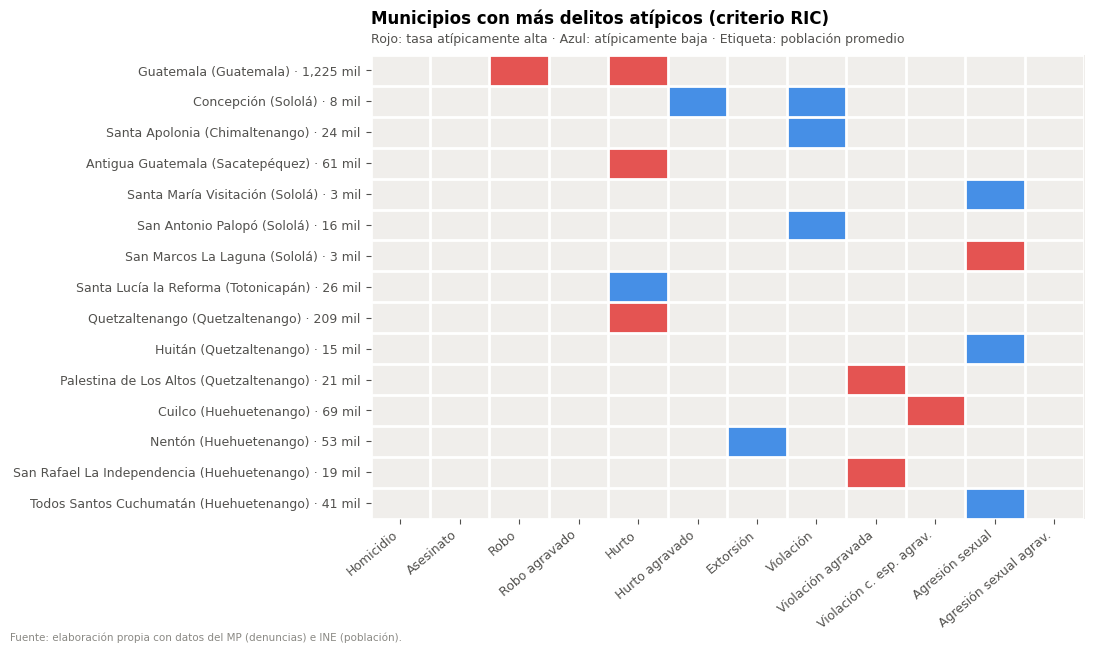

In [16]:
n_atip = atip_ric.sum(axis=1)
top_atip = n_atip[n_atip > 0].sort_values(ascending=False).head(15).index
matriz = atip_ric.loc[top_atip].astype(int) * np.sign(z_robusta.loc[top_atip]).fillna(0)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.imshow(matriz.values, cmap=CMAP_DIVERGENTE, vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(12), [CODIGO_A_CORTO[c] for c in CODIGOS_DELITO], rotation=40, ha="right")
etiquetas = [f"{info.loc[c, 'Etiqueta']} · {info.loc[c, 'Poblacion_prom']/1000:,.0f} mil"
             for c in top_atip]
ax.set_yticks(range(len(top_atip)), etiquetas)
ax.set_xticks(np.arange(-0.5, 12), minor=True)
ax.set_yticks(np.arange(-0.5, len(top_atip)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Municipios con más delitos atípicos (criterio RIC)")
subtitulo(ax, "Rojo: tasa atípicamente alta · Azul: atípicamente baja · Etiqueta: población promedio")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "07_mapa_atipicos", CARPETA_FIG)
plt.show()

## 8. Estabilidad temporal de las tasas

Si el orden de los municipios según su tasa se mantiene de un año a otro, la tasa refleja un **rasgo estructural** del municipio y no un hecho aislado. Se mide con la correlación de Spearman entre las tasas de años consecutivos.

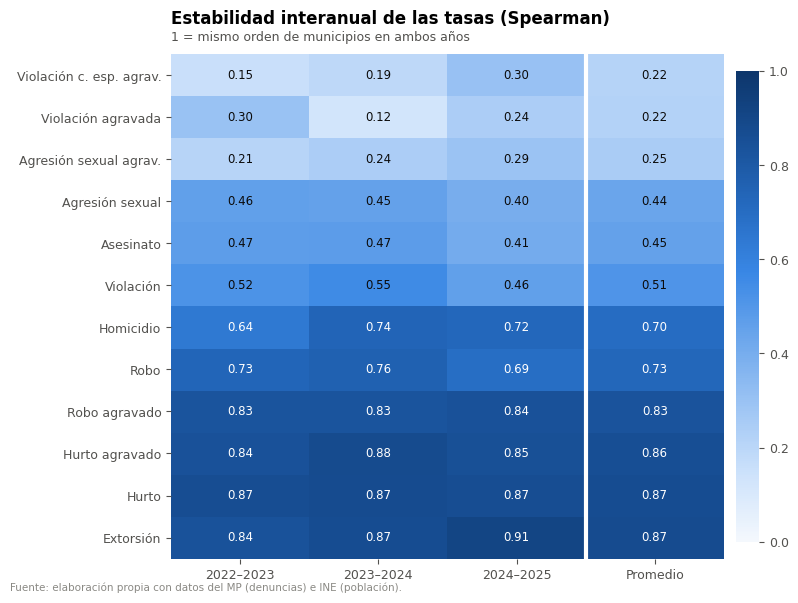

In [17]:
estabilidad = {}
for a1, a2 in zip(ANIOS_ESTUDIO[:-1], ANIOS_ESTUDIO[1:]):
    t1 = tasas_anuales.xs(a1, level="Anio")
    t2 = tasas_anuales.xs(a2, level="Anio")
    estabilidad[f"{a1}–{a2}"] = {c: stats.spearmanr(t1[c], t2[c])[0] for c in CODIGOS_DELITO}
estabilidad = pd.DataFrame(estabilidad)
estabilidad["Promedio"] = estabilidad.mean(axis=1)
estabilidad = estabilidad.sort_values("Promedio").rename(index=CODIGO_A_CORTO)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(estabilidad.values, cmap=CMAP_SECUENCIAL, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(estabilidad.shape[1]), estabilidad.columns)
ax.set_yticks(range(len(estabilidad)), estabilidad.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(estabilidad.shape[0]):
    for j in range(estabilidad.shape[1]):
        v = estabilidad.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.6 else COLOR["texto"])
ax.axvline(2.5, color="white", linewidth=3)
ax.set_title("Estabilidad interanual de las tasas (Spearman)")
subtitulo(ax, "1 = mismo orden de municipios en ambos años")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).outline.set_visible(False)
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "08_estabilidad_temporal", CARPETA_FIG)
plt.show()

## 9. Correlación entre las tasas de los delitos

Ahora que se eliminó el efecto tamaño, las correlaciones reflejan si los delitos **tienden a presentarse juntos** en los mismos municipios. Correlaciones muy altas (|ρ| ≥ 0.8) indicarían **redundancia**: dos variables que aportan casi la misma información y que "pesarían doble" en las distancias.

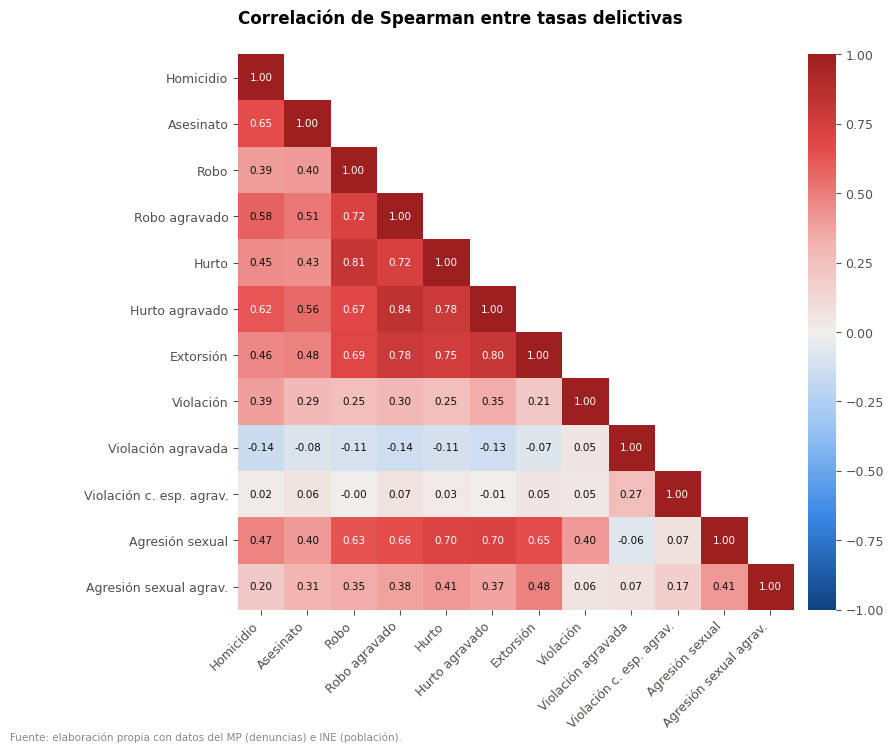

Mediana de ρ (tasas):   0.39   (conteos, notebook 01: 0.63)
Pares con ρ ≥ 0.8: 3   Pares con ρ ≥ 0.7: 9

Los 8 pares más correlacionados:


,Delito A,Delito B,rho
0,Hurto agravado,Robo agravado,0.84
1,Hurto,Robo,0.81
2,Extorsión,Hurto agravado,0.80
3,Extorsión,Robo agravado,0.78
4,Hurto agravado,Hurto,0.78
5,Extorsión,Hurto,0.75
6,Hurto,Robo agravado,0.72
7,Robo agravado,Robo,0.72


In [18]:
corr_tasas = tasas.rename(columns=CODIGO_A_CORTO).corr(method="spearman")
n = len(corr_tasas)

fig, ax = plt.subplots(figsize=(9, 7.5))
mascara = np.triu(np.ones_like(corr_tasas, dtype=bool), k=1)
im = ax.imshow(np.ma.masked_where(mascara, corr_tasas.values), cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(n), corr_tasas.columns, rotation=45, ha="right")
ax.set_yticks(range(n), corr_tasas.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(n):
    for j in range(i + 1):
        v = corr_tasas.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 else COLOR["texto"])
ax.set_title("Correlación de Spearman entre tasas delictivas")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).outline.set_visible(False)
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "09_correlacion_tasas", CARPETA_FIG)
plt.show()

tri = np.tril_indices(n, -1)
pares = pd.DataFrame({"Delito A": corr_tasas.index[tri[0]], "Delito B": corr_tasas.columns[tri[1]],
                      "rho": corr_tasas.values[tri]}).sort_values("rho", ascending=False)
print(f"Mediana de ρ (tasas):   {pares['rho'].median():.2f}   (conteos, notebook 01: 0.63)")
print(f"Pares con ρ ≥ 0.8: {(pares['rho'] >= 0.8).sum()}   Pares con ρ ≥ 0.7: {(pares['rho'] >= 0.7).sum()}")
print("\nLos 8 pares más correlacionados:")
display(pares.head(8).reset_index(drop=True))

## 10. Panorama territorial en tasas

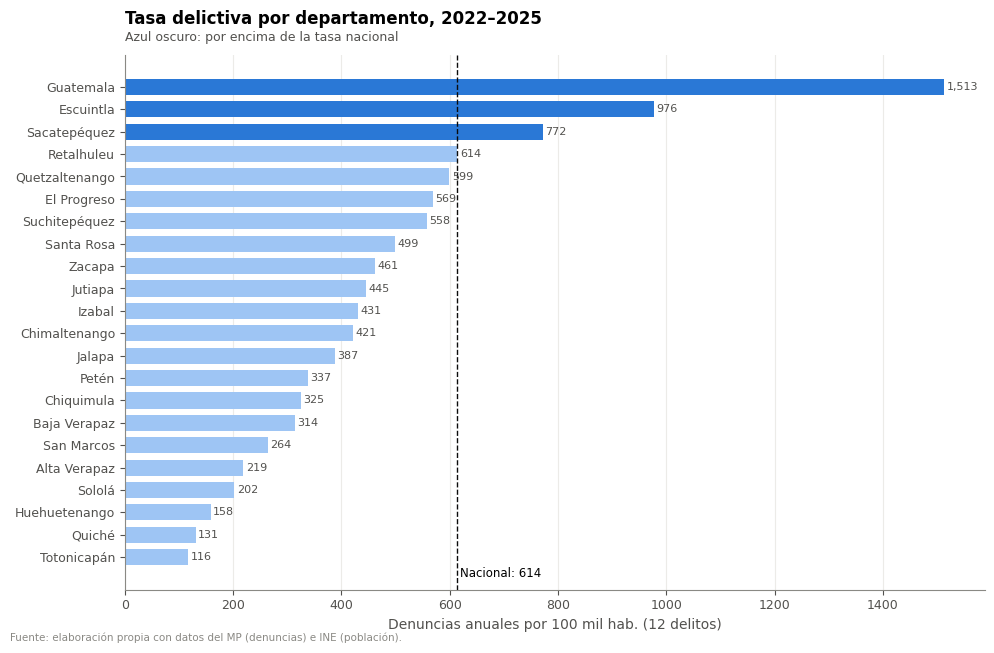

In [19]:
dep = (anual.groupby("Departamento").agg(Denuncias=("Denuncias", "sum"))
       .join(poblacion.groupby("Departamento")["Poblacion"].sum()))
dep["Tasa"] = dep["Denuncias"] / dep["Poblacion"] * 1e5
dep = dep.sort_values("Tasa")
tasa_nac_total = dep["Denuncias"].sum() / dep["Poblacion"].sum() * 1e5

fig, ax = plt.subplots(figsize=(10, 6.5))
colores = [COLOR["azul"] if t >= tasa_nac_total else "#9ec5f4" for t in dep["Tasa"]]
ax.barh(dep.index, dep["Tasa"], color=colores, height=0.72)
ax.axvline(tasa_nac_total, color=COLOR["texto"], linestyle="--", linewidth=1)
ax.text(tasa_nac_total + 5, -0.9, f"Nacional: {tasa_nac_total:,.0f}", fontsize=8.5)
for i, v in enumerate(dep["Tasa"]):
    ax.text(v + 5, i, f"{v:,.0f}", va="center", fontsize=8, color=COLOR["texto_sec"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Denuncias anuales por 100 mil hab. (12 delitos)")
ax.set_title("Tasa delictiva por departamento, 2022–2025")
subtitulo(ax, "Azul oscuro: por encima de la tasa nacional")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "10_tasa_por_departamento", CARPETA_FIG)
plt.show()

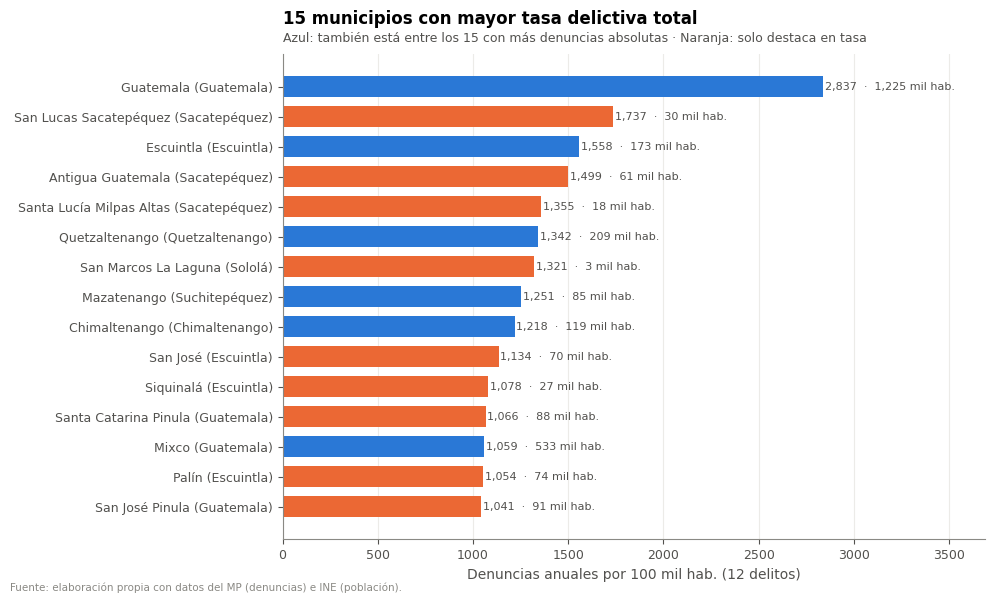

Coinciden 6 de 15 municipios entre el ranking por conteo y por tasa.


In [20]:
top_tasa = info.nlargest(15, "Tasa_total").sort_values("Tasa_total")
top_conteo = set(info.nlargest(15, "Denuncias_total").index)

fig, ax = plt.subplots(figsize=(10, 6))
colores = [COLOR["azul"] if c in top_conteo else COLOR["naranja"] for c in top_tasa.index]
ax.barh(top_tasa["Etiqueta"], top_tasa["Tasa_total"], color=colores, height=0.7)
for i, (v, p) in enumerate(zip(top_tasa["Tasa_total"], top_tasa["Poblacion_prom"])):
    ax.text(v + 10, i, f"{v:,.0f}  ·  {p/1000:,.0f} mil hab.", va="center", fontsize=8,
            color=COLOR["texto_sec"])
ax.set_xlim(0, top_tasa["Tasa_total"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Denuncias anuales por 100 mil hab. (12 delitos)")
ax.set_title("15 municipios con mayor tasa delictiva total")
subtitulo(ax, "Azul: también está entre los 15 con más denuncias absolutas · Naranja: solo destaca en tasa")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "11_top15_tasa_total", CARPETA_FIG)
plt.show()
print(f"Coinciden {len(top_conteo & set(top_tasa.index))} de 15 municipios entre el ranking por conteo y por tasa.")

## 11. Estructura multivariada preliminar

Antes de aplicar algoritmos de agrupamiento conviene comprobar que los datos **tienen estructura de grupos**. Si estuvieran distribuidos al azar, cualquier algoritmo produciría grupos artificiales.

Para este diagnóstico se usa una representación **provisional**: $\log(1 + \text{tasa})$ estandarizada (media 0, desviación 1). La representación definitiva se decidirá y justificará en el notebook de preprocesamiento.

### 11.1 Estadístico de Hopkins

Compara las distancias entre los datos reales con las distancias desde puntos generados al azar:

- $H \approx 0.5$: sin tendencia de agrupamiento (datos aleatorios).
- $H > 0.75$: tendencia de agrupamiento significativa (criterio usual).

Se repite 30 veces con muestras distintas (semilla fija) para reportar un valor estable.

In [21]:
X_diag = StandardScaler().fit_transform(tasas_log)
h_media, h_std = estadistico_hopkins(X_diag, proporcion=0.1, repeticiones=30, semilla=SEMILLA)

# Referencia: el mismo cálculo sobre datos uniformes del mismo tamaño
rng = np.random.default_rng(SEMILLA)
X_unif = rng.uniform(X_diag.min(axis=0), X_diag.max(axis=0), size=X_diag.shape)
h_unif, _ = estadistico_hopkins(X_unif, proporcion=0.1, repeticiones=30, semilla=SEMILLA)

print(f"Hopkins (datos reales):            H = {h_media:.3f} ± {h_std:.3f}")
print(f"Hopkins (referencia aleatoria):    H = {h_unif:.3f}")

Hopkins (datos reales):            H = 0.702 ± 0.010
Hopkins (referencia aleatoria):    H = 0.469


### 11.2 Análisis de componentes principales (PCA)

El PCA resume las 12 tasas en pocas **componentes** que capturan la mayor variación. Sirve para (a) saber cuántas dimensiones "reales" tienen los datos y (b) ver los municipios en 2D.

,Varianza explicada (%),Acumulada (%),Autovalor
CP1,47.85,47.85,5.76
CP2,11.32,59.17,1.36
CP3,9.32,68.49,1.12
CP4,6.96,75.45,0.84
CP5,6.03,81.47,0.73
CP6,5.01,86.49,0.60


Componentes con autovalor > 1 (Kaiser): 3
Componentes para explicar ≥ 80 % de la varianza: 5


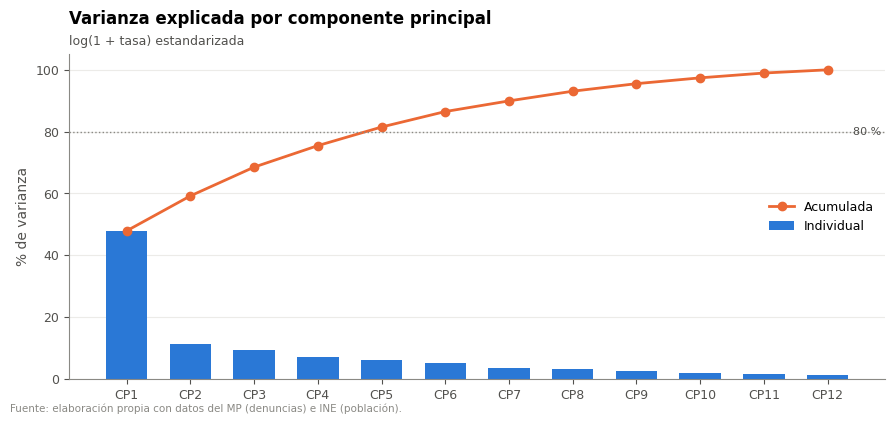

In [22]:
pca = PCA(random_state=SEMILLA).fit(X_diag)
varianza = pd.DataFrame({
    "Varianza explicada (%)": pca.explained_variance_ratio_ * 100,
    "Acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
    "Autovalor": pca.explained_variance_,
}, index=[f"CP{i}" for i in range(1, 13)])
display(varianza.head(6).round(2))
n_kaiser = int((pca.explained_variance_ > 1).sum())
n_80 = int(np.argmax(varianza["Acumulada (%)"].values >= 80) + 1)
print(f"Componentes con autovalor > 1 (Kaiser): {n_kaiser}")
print(f"Componentes para explicar ≥ 80 % de la varianza: {n_80}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(range(1, 13), varianza["Varianza explicada (%)"], color=COLOR["azul"], width=0.65,
       label="Individual")
ax.plot(range(1, 13), varianza["Acumulada (%)"], color=COLOR["naranja"], marker="o", label="Acumulada")
ax.axhline(80, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.text(12.4, 80, "80 %", va="center", fontsize=8, color=COLOR["texto_sec"])
ax.set_xticks(range(1, 13), [f"CP{i}" for i in range(1, 13)])
ax.set_ylim(0, 105)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% de varianza")
ax.set_title("Varianza explicada por componente principal")
subtitulo(ax, "log(1 + tasa) estandarizada")
ax.legend(loc="center right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "12_pca_varianza", CARPETA_FIG)
plt.show()

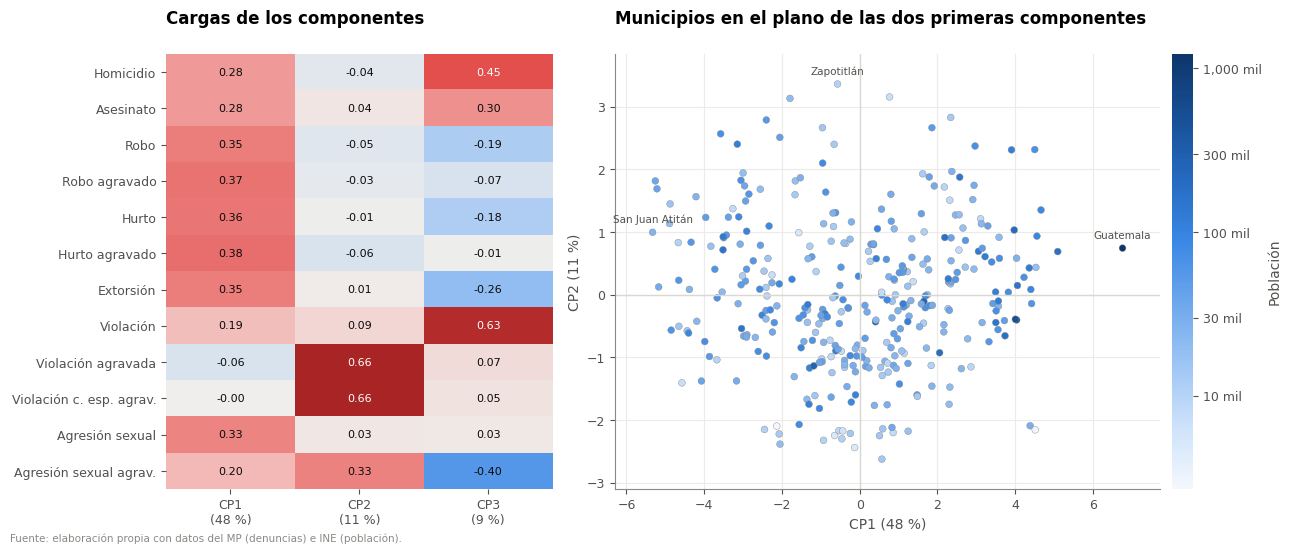

Correlación de Spearman entre CP1 y la población: 0.08


In [23]:
cargas = pd.DataFrame(pca.components_[:3].T, index=[CODIGO_A_CORTO[c] for c in CODIGOS_DELITO],
                      columns=["CP1", "CP2", "CP3"])
comp = pca.transform(X_diag)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
im = ax.imshow(cargas.values, cmap=CMAP_DIVERGENTE, vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(3), [f"CP{i}\n({v:.0f} %)" for i, v in
                         enumerate(varianza["Varianza explicada (%)"][:3], start=1)])
ax.set_yticks(range(12), cargas.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(12):
    for j in range(3):
        v = cargas.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.45 else COLOR["texto"])
ax.set_title("Cargas de los componentes")

ax = axes[1]
sc = ax.scatter(comp[:, 0], comp[:, 1], c=np.log10(info["Poblacion_prom"]), cmap=CMAP_SECUENCIAL,
                s=24, edgecolor=COLOR["gris"], linewidth=0.3)
cb = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
cb.outline.set_visible(False)
ticks = [1e4, 3e4, 1e5, 3e5, 1e6]
cb.set_ticks(np.log10(ticks), labels=[f"{t/1000:,.0f} mil" for t in ticks])
cb.set_label("Población")
for idx in [np.argmax(comp[:, 0]), np.argmin(comp[:, 0]), np.argmax(comp[:, 1])]:
    ax.annotate(info.iloc[idx]["Municipio"], (comp[idx, 0], comp[idx, 1]), fontsize=7.5,
                textcoords="offset points", xytext=(0, 7), ha="center", color=COLOR["texto_sec"])
ax.margins(x=0.08, y=0.08)
ax.axhline(0, color=COLOR["gris_claro"], linewidth=1); ax.axvline(0, color=COLOR["gris_claro"], linewidth=1)
ax.set_xlabel(f"CP1 ({varianza.iloc[0, 0]:.0f} %)")
ax.set_ylabel(f"CP2 ({varianza.iloc[1, 0]:.0f} %)")
ax.set_title("Municipios en el plano de las dos primeras componentes")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "13_pca_cargas_y_municipios", CARPETA_FIG)
plt.show()

print("Correlación de Spearman entre CP1 y la población:",
      f"{stats.spearmanr(comp[:, 0], info['Poblacion_prom'])[0]:.2f}")

## 12. Exportación de la base municipal integrada

Una fila por municipio con: código INE, nombres, población promedio, denuncias por delito (conteos 2022–2025) y **tasas promedio anuales por 100 mil habitantes**. Esta es la entrada del notebook de preprocesamiento.

In [24]:
base = (info[["Departamento", "Municipio", "Poblacion_prom", "Denuncias_total", "Tasa_total"]]
        .join(conteos.add_prefix("n_"))
        .join(tasas.add_prefix("tasa_"))
        .join(catalogo.set_index("Codigo_Municipio")[["Municipio"]].rename(columns={"Municipio": "Municipio_MP"}))
        .reset_index()
        .sort_values("Codigo_Municipio"))

ruta = RUTA_PROCESSED / "base_municipal_2022_2025.csv"
base.to_csv(ruta, index=False, encoding="utf-8-sig")
assert base.shape[0] == 340 and base.filter(like="tasa_").notna().all().all()
print(f"Guardado: {ruta.relative_to(RAIZ)}  ({base.shape[0]} filas × {base.shape[1]} columnas)")
display(base.head(3))

Guardado: data/processed/base_municipal_2022_2025.csv  (340 filas × 31 columnas)


,Codigo_Municipio,Departamento,Municipio,Poblacion_prom,Denuncias_total,Tasa_total,n_homicidio,n_asesinato,n_robo,n_robo_agravado,n_hurto,n_hurto_agravado,n_extorsion,n_violacion,n_violacion_agravada,n_violacion_circ_especiales,n_agresion_sexual,n_agresion_sexual_agravada,tasa_homicidio,tasa_asesinato,tasa_robo,tasa_robo_agravado,tasa_hurto,tasa_hurto_agravado,tasa_extorsion,tasa_violacion,tasa_violacion_agravada,tasa_violacion_circ_especiales,tasa_agresion_sexual,tasa_agresion_sexual_agravada,Municipio_MP
0,101,Guatemala,Guatemala,"1,225,163.25",139031,"2,836.99",2723,875,30695,24018,39559,18466,19298,1677,130,49,1256,285,55.56,17.85,626.35,490.10,807.22,376.81,393.78,34.22,2.65,1.00,25.63,5.82,Guatemala
1,102,Guatemala,Santa Catarina Pinula,"87,869.00",3746,"1,065.79",123,83,454,474,736,523,1204,74,4,4,56,11,35.00,23.61,129.17,134.86,209.40,148.80,342.56,21.05,1.14,1.14,15.93,3.13,Santa Catarina Pinula
2,103,Guatemala,San José Pinula,"90,529.25",3769,"1,040.82",117,49,543,510,647,569,1118,105,13,2,69,27,32.31,13.53,149.95,140.84,178.67,157.13,308.74,29.00,3.59,0.55,19.05,7.46,San José Pinula
